In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%config InlineBackend.figure_format = "retina"

In [230]:
from scipy.optimize import brute

In [3]:
import warnings
warnings.filterwarnings(action = "ignore")

In [277]:
class RSIBackTester():
    '''
    It is a trading strategy implemented based on the RSI (Relative Strength Index).
    Attributes:
    ===========
    df: pd.DataFrame
        The dataframe of closing price that we would apply the trading strategy on it. 
        It must include the only one column (closing price), renamed "price".
    symbol: str
        Instrument ticker.
    periods: int
        It is the period to compute the moving average for both of the UpTrend & DownTrend.
    rsi_upper: int:
        Upper threshold for selling signals.
    rsi_lower: int:
        Lower threshold for buying signals.
    start: str
        Backtest start date, format : 'YYYY-MM-DD'
    end: str
        backtest end date. format: 'YYYY-MM-DD'
    tc: float
        Transaction cost per trade(fractional, e.g., 0.001 = 0.1%).
    Methods:
    ========
    get_data()
    trading_strategy(displaying_mode = None):
    set_parameters(new_periods , new_rsi_upper , new_rsi_lower)
    optimized_trading_strategy(new_periods_range : (start , stop , step) , new_upper_rsi_range : (start , stop , step) , new_lower_rsi_range : (start , stop , step))
    plot_results() 
    '''
    def __init__(self , df , symbol , periods , rsi_upper , rsi_lower , start , end , tc):
        self.df = df
        self.symbol = symbol
        self.periods = periods
        self.rsi_upper = rsi_upper
        self.rsi_lower = rsi_lower
        self.start = start
        self.end = end
        self.tc = tc
        self.get_data()
        self.results = None
        self.KPI = None
        self.KPI_table = None

    def __repr__(self):
        rep = f"RSI_BackTester(Symbol : {self.symbol} | periods : {self.periods} | RSI_Thresh0 : ({self.rsi_upper} , {self.rsi_lower}) | start : {self.start} | end : {self.end} | pct : {self.tc})"
        return rep

    def get_data(self):
        '''Load the raw data and compute the RSI and its related components. '''
        raw = self.df.loc[self.start:self.end]
        raw["UP"] = np.where(raw["price"].diff() > 0 , raw["price"].diff(), 0)
        raw["Down"] = np.where(raw["price"].diff() < 0 , -raw["price"].diff() , 0)
        raw["MA_UP"] = raw["UP"].rolling(window = self.periods).mean()
        raw["MA_Down"] = raw["Down"].rolling(window = self.periods).mean()
        raw["RSI"] = raw["MA_UP"] / (raw["MA_UP"] + raw["MA_Down"])
        raw["RSI"] = raw["RSI"] * 100
        raw = raw.dropna()
        self.data = raw
        return raw

    def trading_strategy(self , displaying_mode = None):
        '''
        Implement the RSI trading strategy & displaying its performance in comparasion with the buy&hold strategy.
        Parameters:
        ===========
        displaying_mode : str , optional
            'tabular' : returns styled KPI table.
            'value' : return the single value: the performance of our trading strategy.
        '''

        data = self.data
        data["position"] = np.where(data["RSI"]>self.rsi_upper , -1 , np.where(data["RSI"]<self.rsi_lower , +1 , 0))
        data["trades"] = data["position"].diff().fillna(0).abs()
        data["log_ret"] = np.log(data["price"]/data["price"].shift(1))
        data["strategy"] = data["position"].shift(1) * data["log_ret"]
        data["strategy_net"] = data["position"].shift(1) * data["log_ret"] - data["trades"] * self.tc
        data["cum_ret"] = np.exp(data["log_ret"].cumsum())
        data["cum_strategy"] = np.exp(data["strategy"].cumsum())
        data["cum_strategy_net"] = np.exp(data["strategy_net"].cumsum())
        data = data.dropna()
        self.results = data

        # Extract final performance values:
        strategy_performance = data["cum_strategy_net"].iloc[-1]
        buy_and_hold_performance = data["cum_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance


        self.KPI = pd.DataFrame(
            {"Strategy" : strategy_performance ,
            "Buy & Hold" : buy_and_hold_performance ,
            "Out Performance" : out_performance,
            "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252,
            "Ann. Return Strategy" : data["strategy_net"].mean() * 252,
            "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252),
            "Ann. Risk Strategy" : np.sqrt(data["strategy_net"].var() * 252),
            } , 
            index = [f"RSI_Upper:{self.rsi_upper} | RSI_Lower:{self.rsi_lower}"]
        )

        self.KPI.index.name = "Performance"

        self.KPI_table = self.KPI.T.style.format("{:.2%}")

        if displaying_mode == "tabular":
            return self.KPI_table
        
        elif displaying_mode == "value":
            return float(strategy_performance)
        
        else:
            print("Display mode not specified.")
            return None

    def plot_results(self):
        '''Plot the RSI trading strategy performance vs the buy&hold strategy.'''
        fig , ax = plt.subplots(figsize = (12,6))
        data = self.results
        ax.plot(data.loc[:, ["cum_ret"]] , label = "Buy&Hold Strategy" , lw = 2 , alpha = .6)
        ax.plot(data.loc[:, ["cum_strategy"]] , label = "RSI Trading Strategy" , lw = 2 ,color ="orange", alpha = .6)
        ax.plot(data.loc[:, ["cum_strategy_net"]] , label = "RSI Net Trading Strategy" , lw = 2 ,color ="cyan", alpha = .9)
        ax.spines[["right" , "top"]].set_visible(False)
        ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        ax.autoscale(enable=True , axis ="x" , tight = True)
        ax.set_xlabel("Date" , fontsize = 13)
        ax.set_title(f"{self.symbol}: RSI | Price" , fontsize = 18)
        ax.grid(ls = ":", lw= .8)

        ax2 = ax.twinx()
        ax2.plot(data.loc[:, ["RSI"]] , label = "RSI" , color = "gray" , ls ="--" , lw = 2 , alpha = 0.6)
        ax2.spines[["right" , "top"]].set_visible(False)
        ax2.autoscale(enable=True , axis ="x" , tight = True)
        ax2.axhline(y=self.rsi_upper , color = "red" , label = f"RSI > {self.rsi_upper} : Selling Signal" , lw = 3)
        ax2.axhline(y=self.rsi_lower , color = "green" , label = f"RSI < {self.rsi_lower} : Buying Signal" , lw = 3)
        ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        ax2.set_yticks(ticks = [self.rsi_lower,self.rsi_upper])
        ax2.set_yticklabels(labels = ["Buying" , "Selling"])
        for label in ax2.get_yticklabels():
            if label.get_text() == "Buying":
                label.set_color("green")
            elif label.get_text() == "Selling":
                label.set_color("red")

        plt.tight_layout()
        plt.show()

    def set_parameter(self, new_periods = None , new_rsi_upper = None , new_rsi_lower = None):
        '''
        update the new periods, new_rsi_upper, and the new_rsi_lower parameters and recalculate the : UP, DoWN,MA_UP ,MA_Down,RSI.
        '''
        if self.data is None or self.data.empty:
            raise AttributeError("Data not loaded. Call get_data() first.")
        new_raw = self.df.loc[self.start:self.end]
        if new_periods is not None:
            self.periods = int(new_periods)
        if new_rsi_upper is not None:
            self.rsi_upper = int(new_rsi_upper)
        if new_rsi_lower is not None:
            self.rsi_lower = int(new_rsi_lower)

        new_raw = self.df.loc[self.start:self.end]
        new_raw["UP"] = np.where(new_raw["price"].diff() > 0 , new_raw["price"].diff(), 0)
        new_raw["Down"] = np.where(new_raw["price"].diff() < 0 , -new_raw["price"].diff() , 0)
        new_raw["MA_UP"] = new_raw["UP"].rolling(window = self.periods).mean()
        new_raw["MA_Down"] = new_raw["Down"].rolling(window = self.periods).mean()
        new_raw["RSI"] = new_raw["MA_UP"] / (new_raw["MA_UP"] + new_raw["MA_Down"])
        new_raw["RSI"] = new_raw["RSI"] * 100
        new_raw = new_raw.dropna()
        self.data = new_raw
        return new_raw

    def optimized_trading_strategy(self, periods_range:tuple , rsi_upper_ranges:tuple , rsi_lower_range:tuple):
        '''
        grid search algorithm using the brute function to find the maximum value of the strategy return.
        Parameters:
        ===========
        periods_range: (start , stop , step)
            it is a range for the periods.

        rsi_upper_ranges: (start , stop , step)
            it is a range to find the best value of the RSI upper threshold.

        rsi_lower_range: (start , stop , step)
            it is the range to find the bes value of the RSI lower threshold.
        
        Returns:
        ========
        best_parameters: ndarray
            Array [periods , rsi_upper , rsi_lower] for the best periods , rsi_upper , rsi_lower.
        best_strategy: DataFrame/Style
        '''

        def objective_function(x):
            self.set_parameter(x[0] , x[1] , x[2])
            values = self.trading_strategy(displaying_mode="value")
            return -values

        print("starting optimization ... This may take time depending on the range size.")
        res = brute(objective_function , ranges = (periods_range , rsi_upper_ranges , rsi_lower_range))
        best_periods = res[0]
        best_rsi_upper = res[1]
        best_rsi_lower = res[2]
        print(f"Optimal Parameters found : periods {best_periods} | best Upper_RSI : {best_rsi_upper} | best Lower_RSI : {best_rsi_lower}")
        self.set_parameter(new_periods=best_periods , new_rsi_upper=best_rsi_upper , new_rsi_lower=best_rsi_lower)
        
        
        return self.trading_strategy(displaying_mode="tabular")

In [262]:
df = pd.read_csv("forex_pairs.csv" , index_col=["Date"] , parse_dates=["Date"])
df.columns

Index(['AUDEUR=X', 'EURUSD=X', 'USDGBP=X'], dtype='object')

In [263]:
symbol = 'EURUSD=X'

In [264]:
df = df.loc[: , symbol].to_frame()
df.columns = ["price"]

In [265]:
df.columns

Index(['price'], dtype='object')

In [266]:
rsi = RSIBackTester(df ,symbol = symbol , start = "2004-01-01" , end = "2020-06-30" , periods=20 , rsi_lower=30 , rsi_upper=70 , tc= 0.00007)

In [267]:
print(rsi)

RSI_BackTester(Symbol : EURUSD=X | periods : 20 | RSI_Thresh0 : (70 , 30) | start : 2004-01-01 | end : 2020-06-30 | pct : 7e-05)


In [268]:
rsi.get_data()

,price,UP,Down,MA_UP,MA_Down,RSI
Date,,,,,,
2004-01-28,1.244199,0.000000,0.019496,0.004610,0.005310,46.472973
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086
...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190


In [269]:
rsi.trading_strategy(displaying_mode="tabular")

Performance,RSI_Upper:70 | RSI_Lower:30
Strategy,150.49%
Buy & Hold,90.40%
Out Performance,60.09%
Ann. Return Buy & Hold,-0.60%
Ann. Return Strategy,2.42%
Ann. Risk Buy & Hold,12.04%
Ann. Risk Strategy,5.48%


In [270]:
rsi.results

,price,UP,Down,MA_UP,MA_Down,RSI,position,trades,log_ret,strategy,strategy_net,cum_ret,cum_strategy,cum_strategy_net
Date,,,,,,,,,,,,,,
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150,0,0.0,-0.002572,-0.0,-0.0,0.997431,1.000000,1.000000
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310,0,0.0,0.004665,0.0,0.0,1.002095,1.000000,1.000000
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573,0,0.0,-0.002814,-0.0,-0.0,0.999279,1.000000,1.000000
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086,0,0.0,0.008164,0.0,0.0,1.007471,1.000000,1.000000
2004-02-04,1.253997,0.000503,0.000000,0.004740,0.005244,47.471521,0,0.0,0.000401,0.0,0.0,1.007875,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713,0,0.0,0.002892,0.0,0.0,0.909207,1.539634,1.504897
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668,0,0.0,-0.005449,-0.0,-0.0,0.904266,1.539634,1.504897
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190,0,0.0,-0.002562,-0.0,-0.0,0.901953,1.539634,1.504897


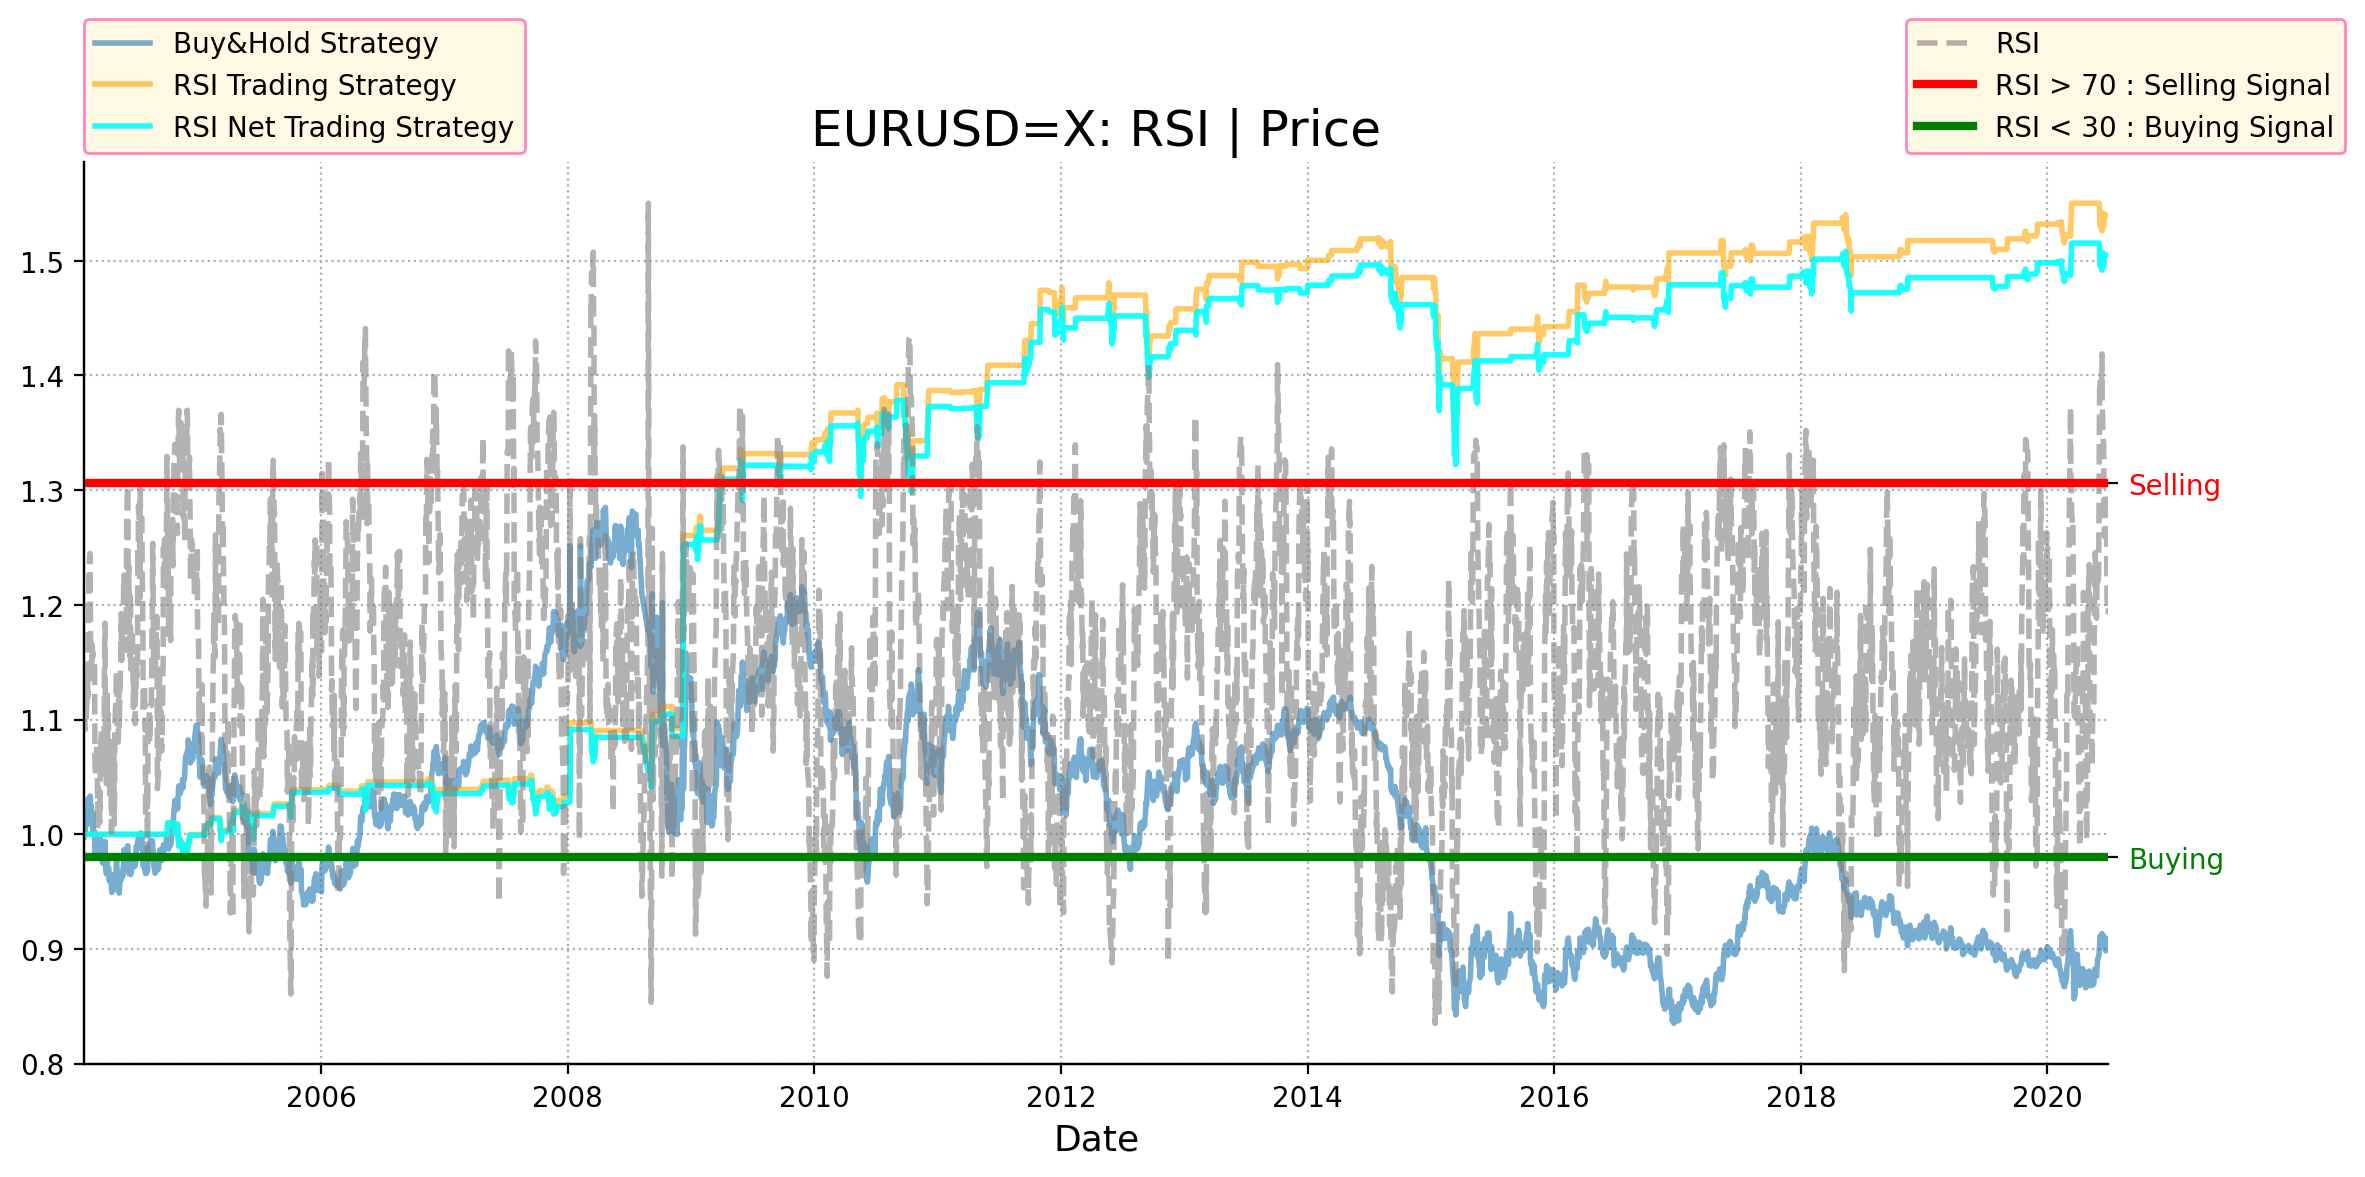

In [271]:
rsi.plot_results()

In [272]:
rsi.set_parameter(10,80,20)

,price,UP,Down,MA_UP,MA_Down,RSI
Date,,,,,,
2004-01-14,1.265102,0.000000,0.013490,0.004020,0.003329,54.699583
2004-01-15,1.260097,0.000000,0.005006,0.004020,0.003830,51.211783
2004-01-16,1.239803,0.000000,0.020294,0.004020,0.005859,40.692374
2004-01-19,1.235407,0.000000,0.004396,0.002970,0.006299,32.041819
2004-01-20,1.258907,0.023500,0.000000,0.004979,0.006299,44.149844
...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.002537,0.002736,48.116133
2020-06-25,1.125087,0.000000,0.006147,0.002205,0.003351,39.689538
2020-06-26,1.122208,0.000000,0.002879,0.002205,0.002865,43.491805


In [273]:
rsi.trading_strategy(displaying_mode="tabular")

Performance,RSI_Upper:80 | RSI_Lower:20
Strategy,142.27%
Buy & Hold,88.90%
Out Performance,53.37%
Ann. Return Buy & Hold,-0.70%
Ann. Return Strategy,2.08%
Ann. Risk Buy & Hold,12.05%
Ann. Risk Strategy,5.67%


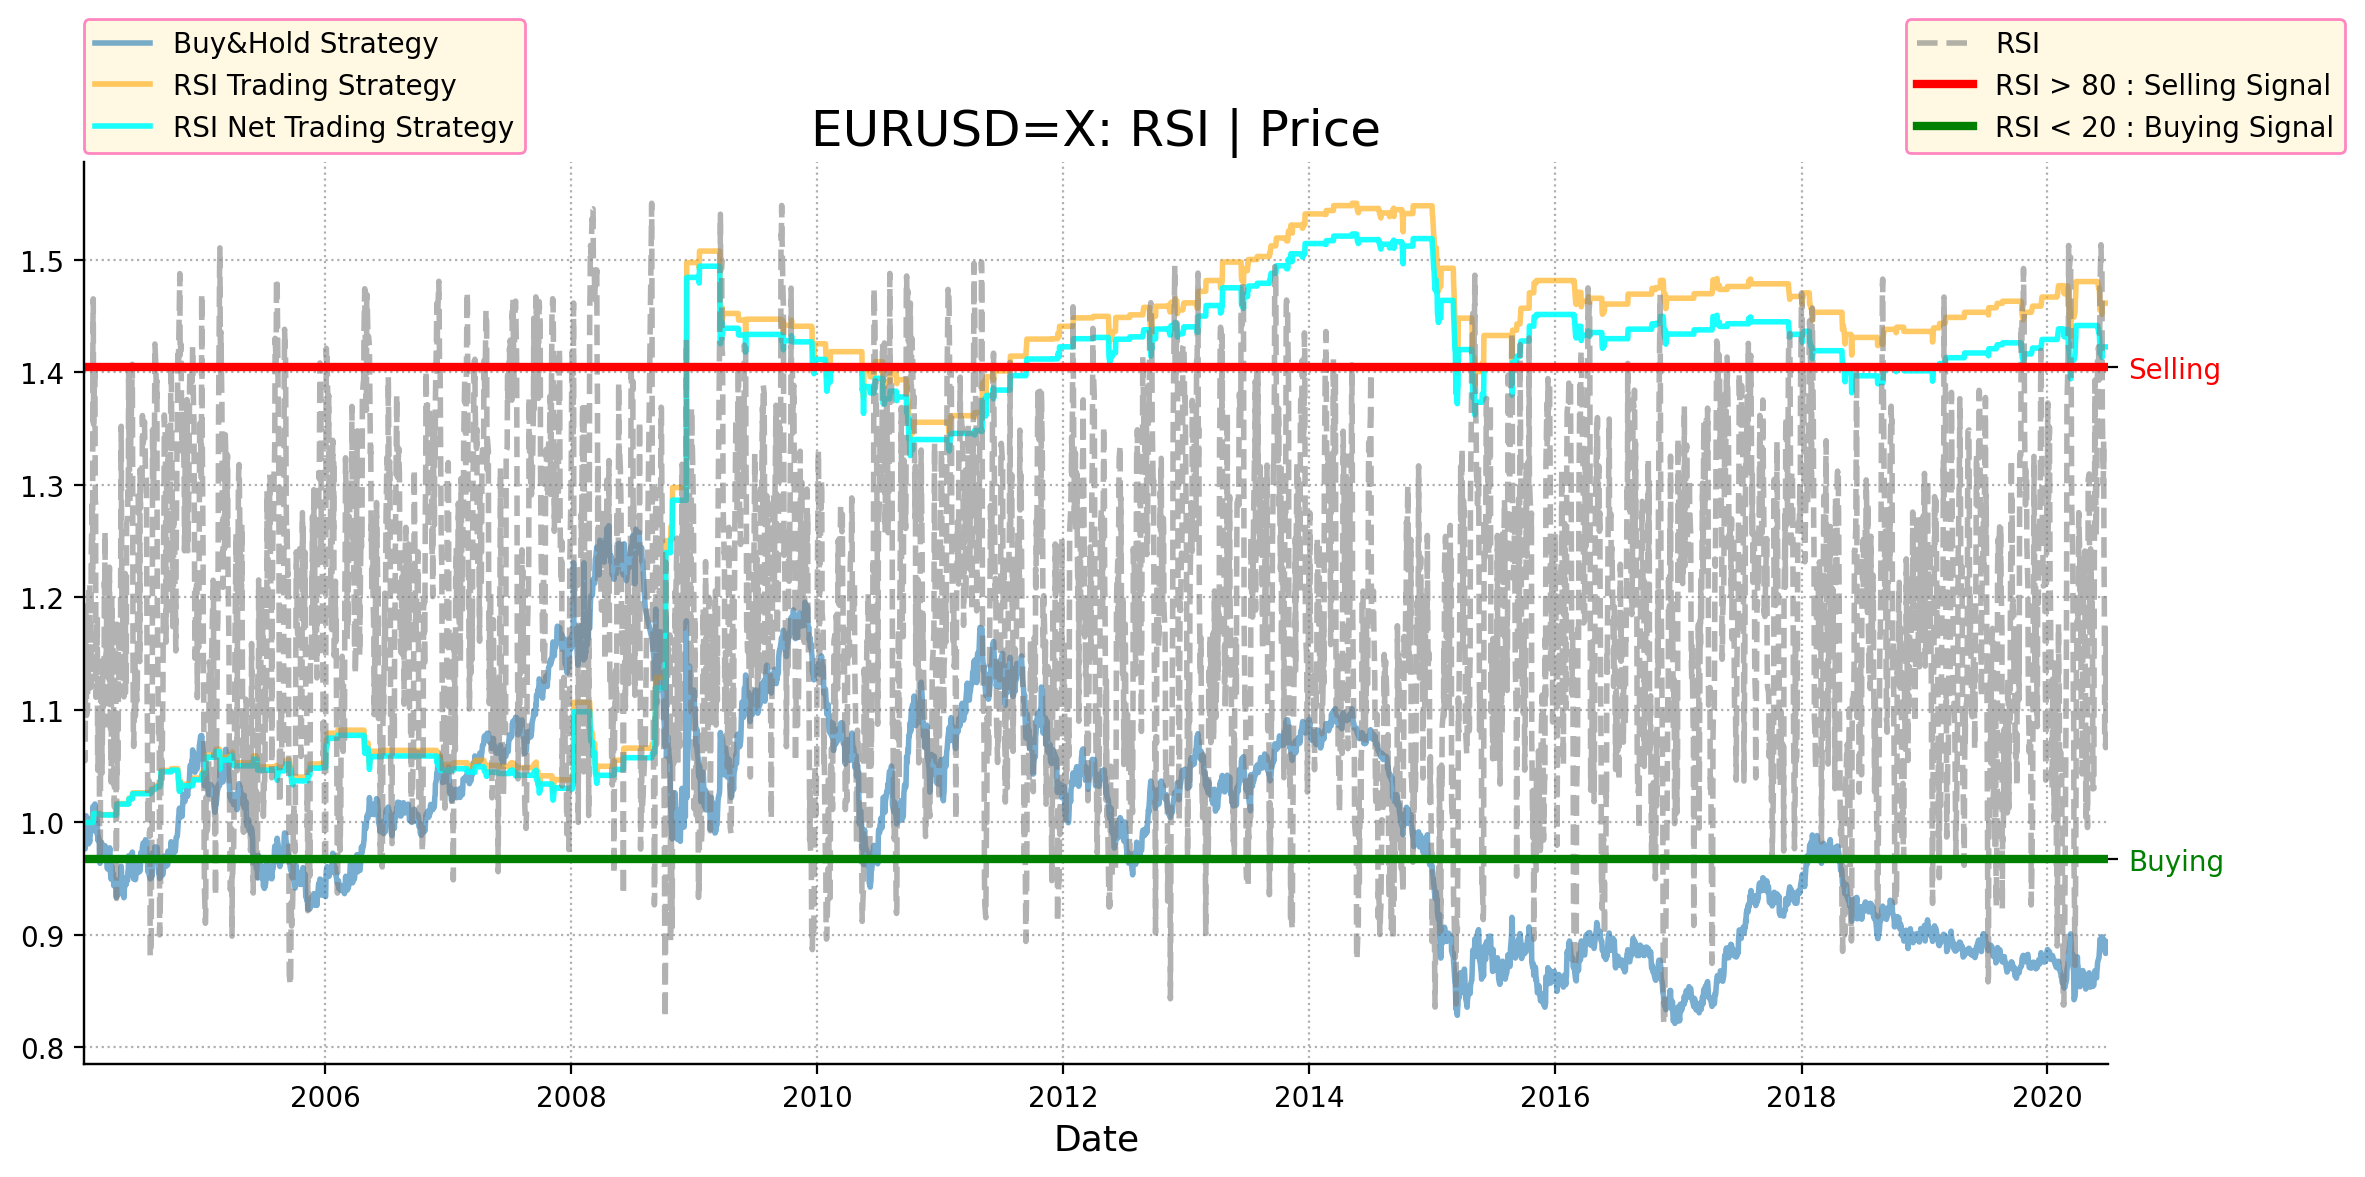

In [274]:
rsi.plot_results()

In [275]:
rsi.RSI_optimized_strategy(periods_range = (1,30,1) , rsi_lower_range = (10,40,1) , rsi_upper_ranges = (50,100,1))

starting optimization ... This may take time depending on the range size.
Optimal Parameters found : periods 9.0 | best Upper_RSI : 56.0 | best Lower_RSI : 40.95


Performance,RSI_Upper:56 | RSI_Lower:40
Strategy,404.11%
Buy & Hold,87.97%
Out Performance,316.14%
Ann. Return Buy & Hold,-0.76%
Ann. Return Strategy,8.25%
Ann. Risk Buy & Hold,12.05%
Ann. Risk Strategy,10.87%


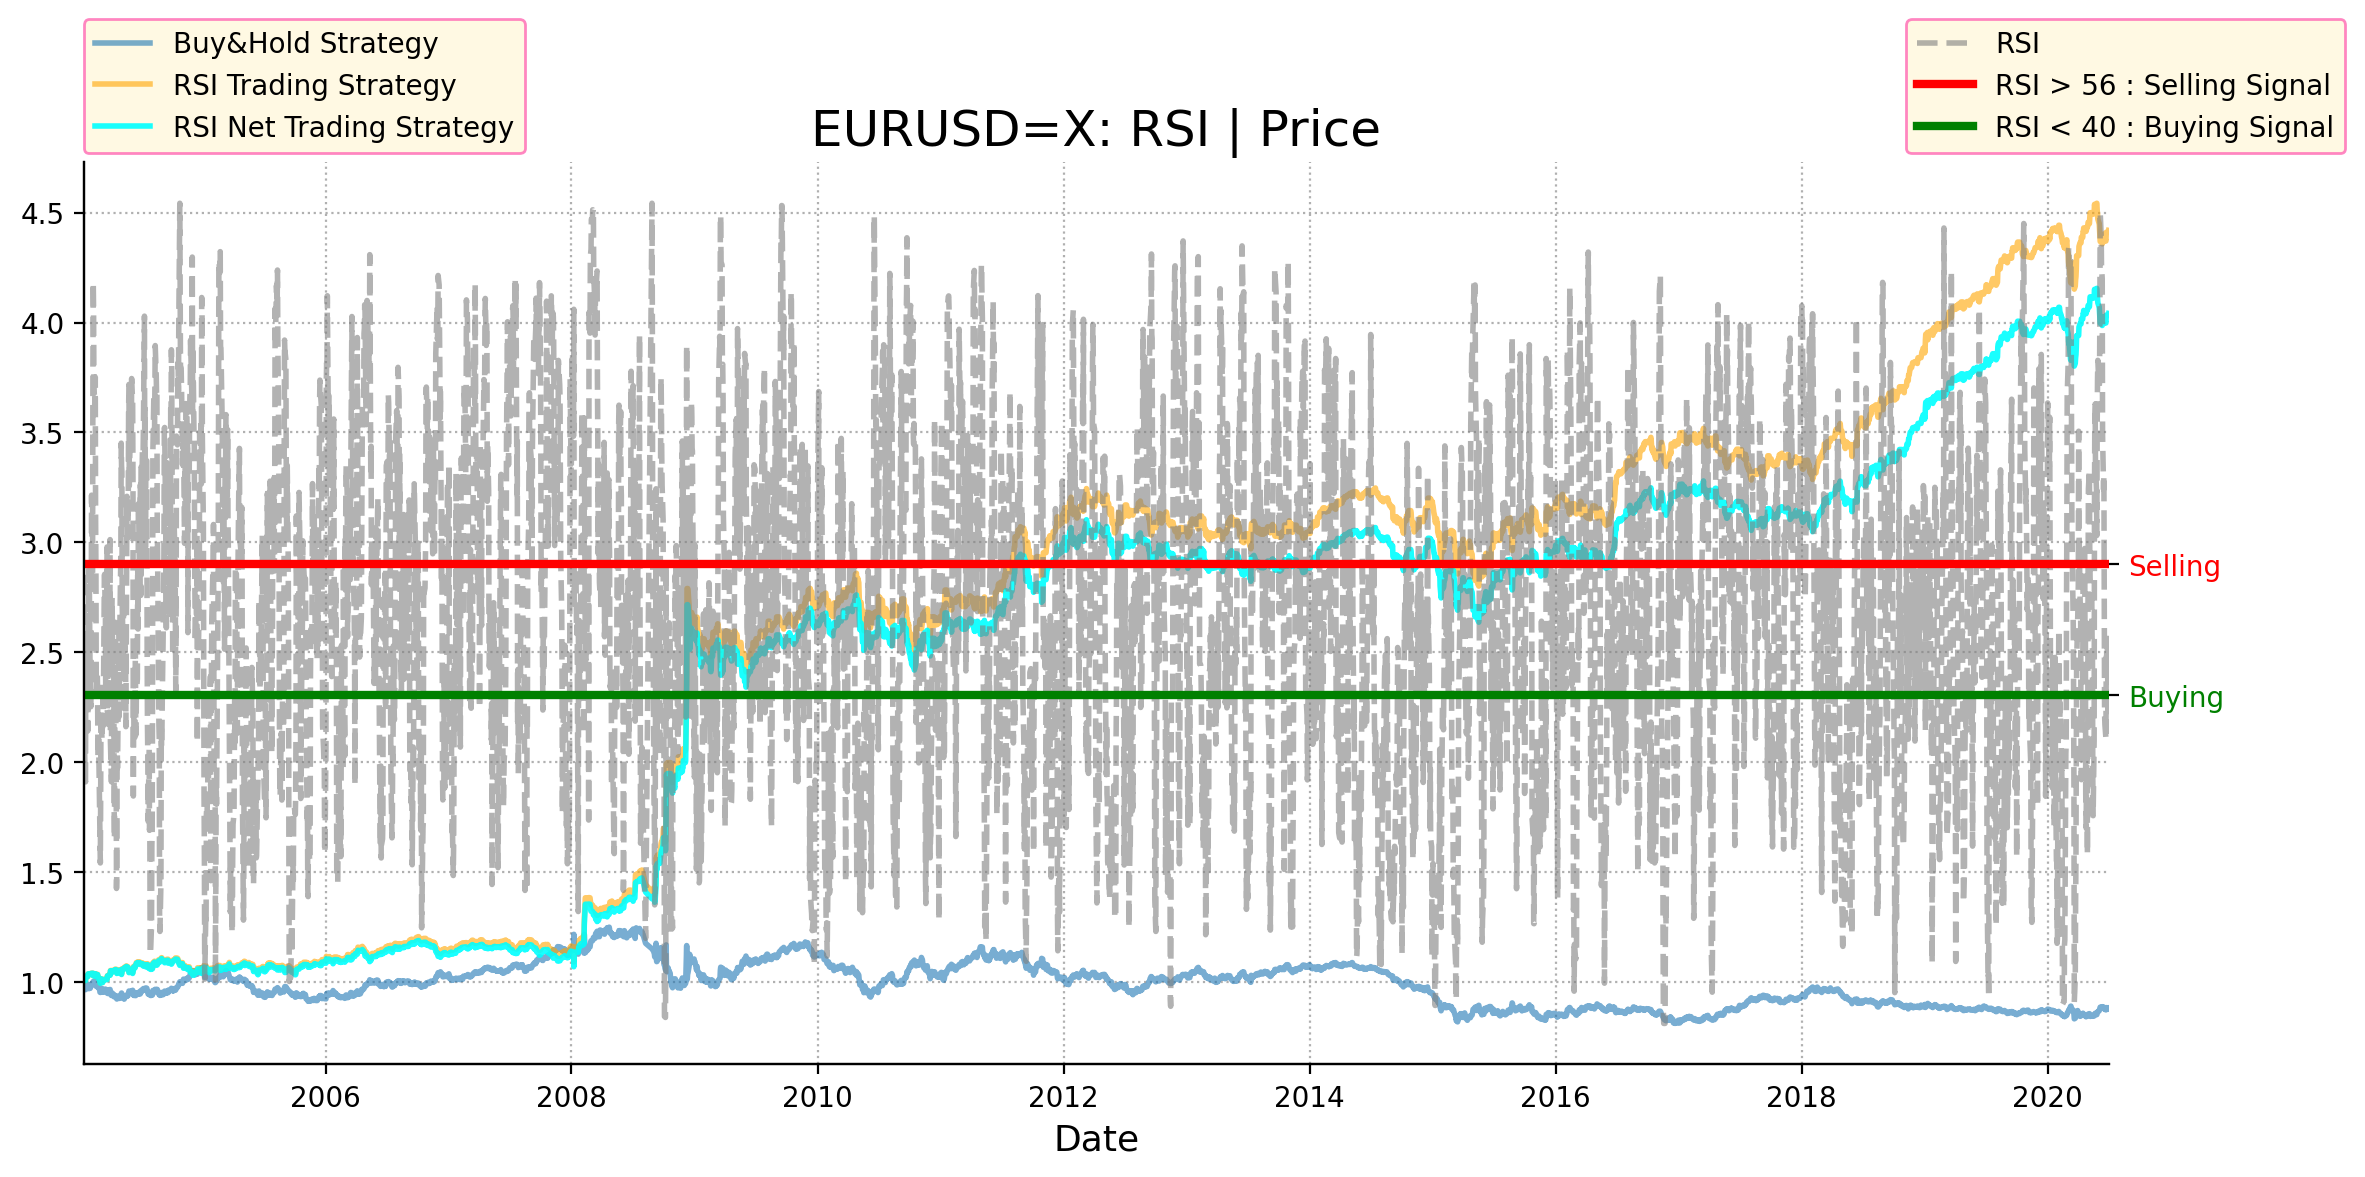

In [276]:
rsi.plot_results()